# Lab — Support Vector Machines from scratch
**Machine Learning SUP'COM workshop**

> Logistic Regression and SVM solve the **same classification problem**, but they care about **different things**.

- Logistic Regression asks: *what is the probability of class 1?*
- SVM asks: *where is the boundary that leaves the **widest safe zone** between the classes?*

How this lab works (same rules as the logistic regression lab):

- Fill in every `# TODO` and replace each `raise NotImplementedError`.
- Run the cells **in order**.
- Compare your outputs with each **Check yourself** cell before moving on.
- Cells marked `# ---- PROVIDED` are complete: just run and read them.
- Write short answers where you see *Your answer:* ...

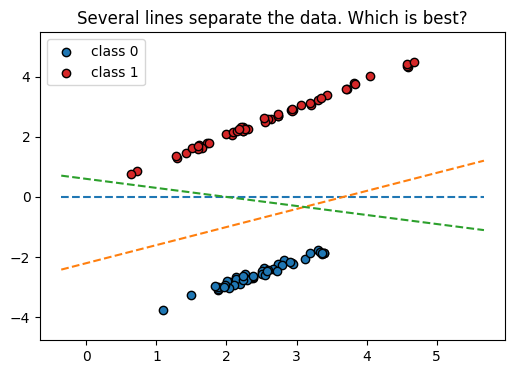

In [1]:
# ---- PROVIDED
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_classification

plt.rcParams["figure.figsize"] = (6, 4)
np.set_printoptions(precision=4, suppress=True)

X, y = make_classification(
    n_samples=100,
    n_features=2,
    n_redundant=0,
    n_informative=2,
    n_clusters_per_class=1,
    class_sep=2.5,
    random_state=42
)

x1_line = np.linspace(X[:, 0].min() - 1, X[:, 0].max() + 1, 100)
plt.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", edgecolor="k", label="class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  edgecolor="k", label="class 1")
for slope, intercept in [(0.0, 0.0), (0.6, -2.2), (-0.3, 0.6)]:
    plt.plot(x1_line, slope * x1_line + intercept, "--")
plt.ylim(X[:, 1].min() - 1, X[:, 1].max() + 1)
plt.title("Several lines separate the data. Which is best?")
plt.legend()
plt.show()

Same dataset as the logistic regression lab. All three dashed lines separate the classes perfectly.

> **Which one would you trust most on new data, and why?**

*Answer:* the one that stays farthest from both classes. A line passing very close to some points is risky: a new point slightly different from the training points could land on the wrong side.

## Part A. Score, labels and margin

### Task 1. Labels in $\{-1, +1\}$

Like logistic regression, a linear SVM computes a score

$$
f(x) = w^T x + b
$$

and $f(x) = 0$ is the decision boundary. The prediction is the **sign** of $f(x)$: no sigmoid, no probability.

SVM writes the classes as $y \in \{-1, +1\}$ because then **one expression**, $y_i f(x_i)$, is positive when the point is correctly classified and negative when it is not.

In [2]:
y_svm = np.where(y == 0, -1, 1)

print("original labels:", y[:8])
print("SVM labels:     ", y_svm[:8])

original labels: [0 0 1 0 0 0 0 1]
SVM labels:      [-1 -1  1 -1 -1 -1 -1  1]


**Check yourself:** `[-1 -1 1 -1 -1 -1 -1 1]`.

> Why would the trick $y_i f(x_i)$ **not** work with labels in $\{0, 1\}$?

*Answer:* for every class-0 example, $y_i f(x_i) = 0 \times f(x_i) = 0$, whatever the score: we could no longer tell a correct class-0 prediction from a wrong one.

### Task 2. Margins and margin width

The quantity $y_i f(x_i)$ is the (functional) **margin** of example $i$. SVM wants every point correct **with a safety margin**: $y_i f(x_i) \ge 1$.

| Line | Equation |
|---|---|
| decision boundary | $f(x) = 0$ |
| positive margin | $f(x) = +1$ |
| negative margin | $f(x) = -1$ |

The corridor between the two margin lines has width $\dfrac{2}{\|w\|}$. So **small weights ⇔ wide margin**.

In [3]:
def margins(X, y, w, b):
    return y * (X @ w + b)


def margin_width(w):
    return 2 / np.linalg.norm(w)


Xt = np.array([[0, 0], [-1, 0], [2, 2], [3, 2]], dtype=float)
yt = np.array([-1, -1, 1, 1])

for w_t, b_t in [(np.array([0.5, 0.5]), -1.0), (np.array([1.0, 1.0]), -2.0)]:
    print("w =", w_t, "b =", b_t, "-> margins", margins(Xt, yt, w_t, b_t),
          "width", round(margin_width(w_t), 3))

w = [0.5 0.5] b = -1.0 -> margins [1.  1.5 1.  1.5] width 2.828
w = [1. 1.] b = -2.0 -> margins [2. 3. 2. 3.] width 1.414


**Check yourself:** `[1. 1.5 1. 1.5]` with width `2.828`, then `[2. 3. 2. 3.]` with width `1.414`.

> Both $(w, b)$ pairs describe the **same line** and both satisfy $y_i f(x_i) \ge 1$ for every point. Which one would SVM choose, and why? Which points touch the margin lines in the first case?

*Answer:* the first one, $w = (0.5, 0.5)$: smaller $\|w\|$, so a wider corridor (2.828 instead of 1.414). Points 0 and 2 (margin exactly 1) touch the margin lines: they are the **support vectors**.

### Visualizing the margin

The function below draws a linear model given by $(w, b)$: regions, boundary (solid), margins (dashed), and optionally circles some points. To see what we are aiming for, we borrow the answer from scikit-learn for one cell.

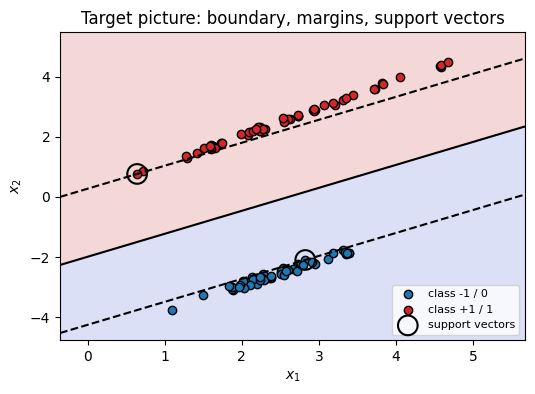

In [4]:
# ---- PROVIDED
from sklearn.svm import SVC


def plot_svm(w, b, X, y, title, support=None, ax=None):
    if ax is None:
        ax = plt.gca()

    x1_min, x1_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    x2_min, x2_max = X[:, 1].min() - 1, X[:, 1].max() + 1
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                           np.linspace(x2_min, x2_max, 300))
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    F = (grid @ w + b).reshape(xx1.shape)

    ax.contourf(xx1, xx2, np.sign(F), alpha=0.2, cmap="coolwarm")
    ax.contour(xx1, xx2, F, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])

    neg, pos = (y <= 0), (y > 0)
    ax.scatter(X[neg, 0], X[neg, 1], c="tab:blue", edgecolor="k", label="class -1 / 0")
    ax.scatter(X[pos, 0], X[pos, 1], c="tab:red",  edgecolor="k", label="class +1 / 1")
    if support is not None:
        ax.scatter(X[support, 0], X[support, 1], s=200, facecolors="none",
                   edgecolors="k", linewidths=1.5, label="support vectors")
    ax.set_xlabel("$x_1$")
    ax.set_ylabel("$x_2$")
    ax.set_title(title)
    ax.legend(loc="lower right", fontsize=8)


preview = SVC(kernel="linear", C=1.0).fit(X, y)
plot_svm(preview.coef_[0], preview.intercept_[0], X, y_svm,
         "Target picture: boundary, margins, support vectors", support=preview.support_)
plt.show()

Only a **few** circled points touch the dashed lines. These **support vectors** hold the boundary in place, like pins.

## Part B. The hinge loss

### Task 3. Hinge loss

> **How do we know if the prediction is good?** For SVM: correct **with a margin of at least 1**.

$$
L_i = \max\big(0,\; 1 - y_i f(x_i)\big)
$$

```text
margin y·f(x) ≥ 1   → loss = 0              correct and safe
0 < y·f(x) < 1      → small positive loss   correct, but inside the corridor
y·f(x) < 0          → large loss            wrong side of the boundary
```

[0.  0.  0.5 1.  2.  4. ]


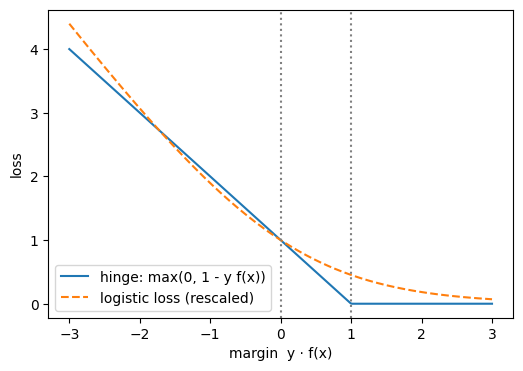

In [5]:
def hinge(margin):
    return np.maximum(0, 1 - margin)


print(hinge(np.array([3.0, 1.0, 0.5, 0.0, -1.0, -3.0])))

m_values = np.linspace(-3, 3, 300)
plt.plot(m_values, hinge(m_values), label="hinge: max(0, 1 - y f(x))")
plt.plot(m_values, np.log(1 + np.exp(-m_values)) / np.log(2), "--",
         label="logistic loss (rescaled)")
plt.axvline(0, color="gray", linestyle=":")
plt.axvline(1, color="gray", linestyle=":")
plt.xlabel("margin  y · f(x)")
plt.ylabel("loss")
plt.legend()
plt.show()

**Check yourself:** `[0. 0. 0.5 1. 2. 4.]`.

> The logistic loss is never exactly 0, the hinge loss is. What does that mean for **which points influence the boundary** in each model?

*Answer:* in logistic regression every point keeps pulling a little on the boundary. With the hinge loss, points with margin $\ge 1$ contribute nothing: only the points on or inside the margin (the support vectors) influence the result.

## Part C. Build the model

### Task 4. The `LinearSVMScratch` class

The soft-margin SVM minimises

$$
J(w, b) = \underbrace{\frac12 \|w\|^2}_{\text{wide margin}} \;+\; C \,\underbrace{\frac1m \sum_{i=1}^{m} \max\big(0,\, 1 - y_i f(x_i)\big)}_{\text{few violations}}
$$

The hinge has a corner at margin = 1, so we use its slope on each side (a *subgradient*). Only the **violating** points (margin $< 1$) contribute:

$$
\nabla_w J = w - \frac{C}{m} \sum_{i:\, y_i f(x_i) < 1} y_i x_i,
\qquad
\frac{\partial J}{\partial b} = - \frac{C}{m} \sum_{i:\, y_i f(x_i) < 1} y_i
$$

$$
w \leftarrow w - \eta \nabla_w J, \qquad b \leftarrow b - \eta \frac{\partial J}{\partial b}
$$

Same structure as `LogisticRegressionScratch`: `__init__` stores hyperparameters, `fit` learns `self.w` and `self.b`, `predict` uses them. Only the loss and its gradient change.

Hint: if `violating` is a boolean mask, `y[violating] @ X[violating]` computes $\sum y_i x_i$ over the violating points.

In [6]:
class LinearSVMScratch:

    def __init__(self, lr=0.01, epochs=1000, C=1.0):
        self.lr = lr
        self.epochs = epochs
        self.C = C

    def fit(self, X, y):
        m, n = X.shape

        self.w = np.zeros(n)
        self.b = 0.0
        self.loss_history = []

        for epoch in range(self.epochs):
            # 1. Scores and margins
            f = X @ self.w + self.b
            margins_i = y * f

            # 2. Objective
            loss = 0.5 * self.w @ self.w + self.C * np.mean(np.maximum(0, 1 - margins_i))
            self.loss_history.append(loss)

            # 3. Violating points
            violating = margins_i < 1

            # 4. Subgradients
            dw = self.w - (self.C / m) * (y[violating] @ X[violating])
            db = -(self.C / m) * np.sum(y[violating])

            # 5. Update
            self.w = self.w - self.lr * dw
            self.b = self.b - self.lr * db

        return self

    def predict(self, X):
        return np.where(X @ self.w + self.b >= 0, 1, -1)

### Task 5. Train the scratch SVM

Learned w: [-0.1597  0.4387]
Learned b: 0.4256
Training accuracy: 1.0
Margin width: 4.284


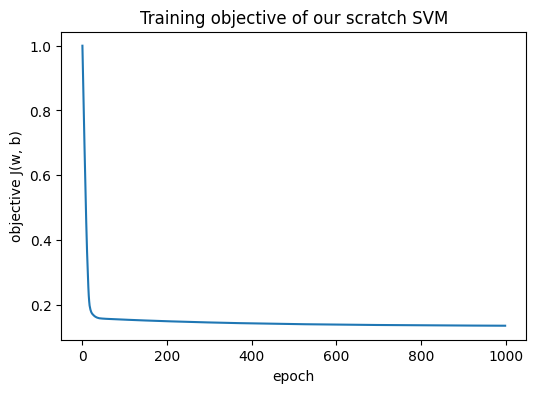

In [7]:
model = LinearSVMScratch(lr=0.01, epochs=1000, C=1.0)

model.fit(X, y_svm)
pred = model.predict(X)

print("Learned w:", model.w)
print("Learned b:", round(model.b, 4))
print("Training accuracy:", np.mean(pred == y_svm))
print("Margin width:", round(margin_width(model.w), 3))

plt.plot(model.loss_history)
plt.xlabel("epoch")
plt.ylabel("objective J(w, b)")
plt.title("Training objective of our scratch SVM")
plt.show()

**Check yourself:** `w = [-0.1597 0.4387]`, `b ≈ 0.4256`, accuracy `1.0`, width `4.284`.

### Task 6. Which points matter?

For our model, the points that influence the boundary are those with $y_i f(x_i) \le 1$. Gradient descent never lands *exactly* on 1, so we use a small tolerance: $y_i f(x_i) \le 1.05$.

Points on or inside the margin: 37


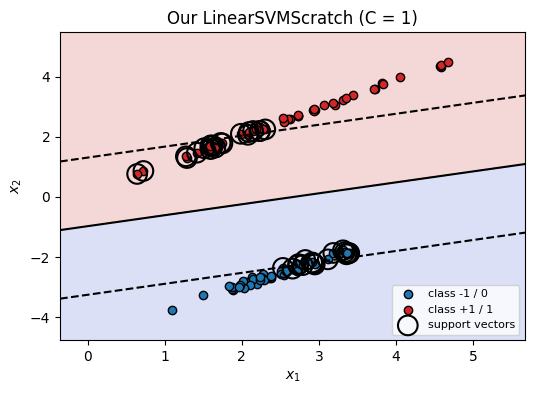

In [8]:
support_scratch = np.where(margins(X, y_svm, model.w, model.b) <= 1 + 0.05)[0]

print("Points on or inside the margin:", len(support_scratch))
plot_svm(model.w, model.b, X, y_svm, "Our LinearSVMScratch (C = 1)", support=support_scratch)
plt.show()

**Check yourself:** `37` points.

> The target picture had only 2 support vectors. Why does our model have so many points inside the corridor? (Hint: look at the objective. What does $C$ balance?)

*Answer:* with this $C$, the $\frac12\|w\|^2$ term wins: the model prefers a wide corridor and accepts that many points sit inside it (each costs only a small hinge loss). Increasing $C$ makes violations more expensive.

## Part D. Understanding $C$

### Task 7. Three values of $C$

$C$ is the **price of a violation**.

- **Small $C$:** violations are cheap → mostly minimise $\|w\|$ → very wide margin, many points inside.
- **Large $C$:** violations are expensive → narrower margin, few violations.

Predict what you will see before running.

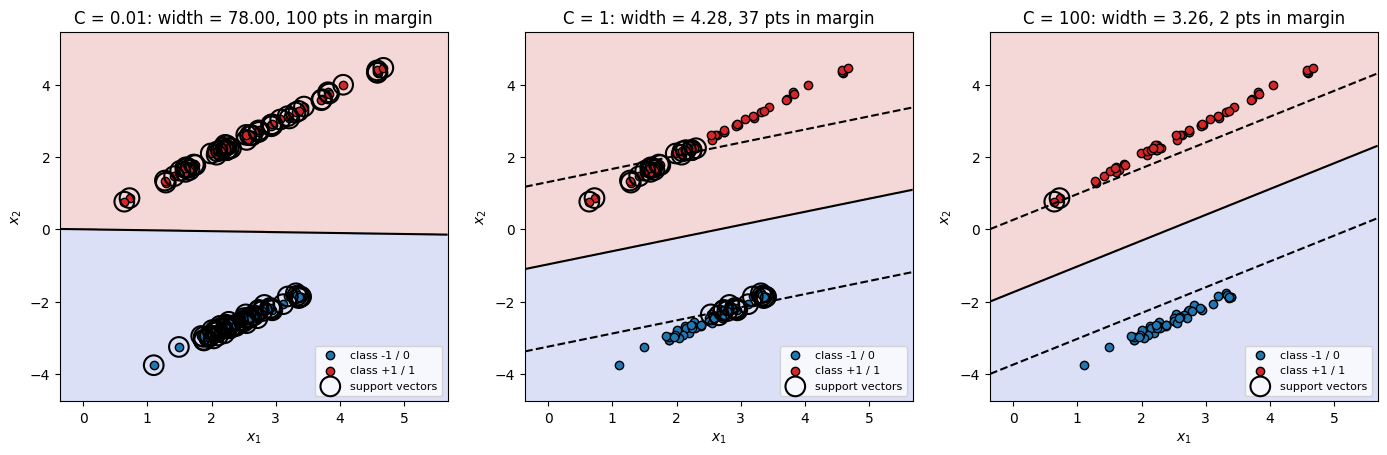

In [9]:
C_values = [0.01, 1, 100]

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
for ax, C in zip(axes, C_values):
    m_C = LinearSVMScratch(lr=0.01, epochs=1000, C=C).fit(X, y_svm)
    support_C = np.where(margins(X, y_svm, m_C.w, m_C.b) <= 1 + 0.05)[0]
    width = margin_width(m_C.w)
    plot_svm(m_C.w, m_C.b, X, y_svm,
             f"C = {C}: width = {width:.2f}, {len(support_C)} pts in margin",
             support=support_C, ax=ax)
plt.show()

**Check yourself:** widths `78.00`, `4.28`, `3.26`; points in the margin `100`, `37`, `2`.

> With $C = 0.01$ you cannot see the dashed lines at all. Where are they? On noisy data, which extreme risks **overfitting** and which risks **underfitting**?

*Answer:* the corridor is about 78 units wide, so the margin lines are far outside the plot and every point is inside the margin. Very large $C$ risks overfitting (it bends to satisfy every single point); very small $C$ risks underfitting (it barely looks at the data).

## Part E. Compare with scikit-learn

### Task 8. `SVC` with a linear kernel

sklearn w: [-0.3374  0.4422]
sklearn b: 0.878
sklearn accuracy: 1.0
support_: [ 8 82]
n_support_: [1 1]


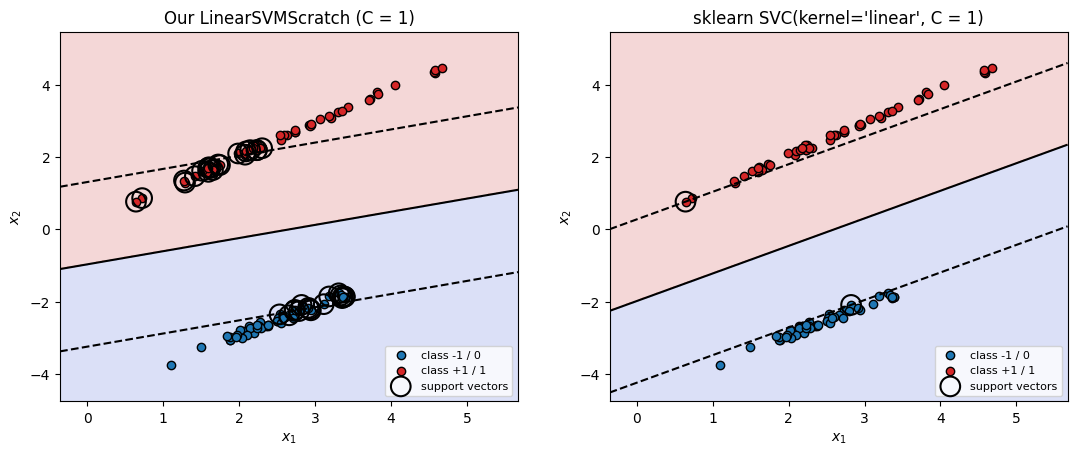

In [10]:
sk_model = SVC(kernel="linear", C=1.0)
sk_model.fit(X, y)
sk_pred = sk_model.predict(X)

print("sklearn w:", sk_model.coef_[0])
print("sklearn b:", round(sk_model.intercept_[0], 4))
print("sklearn accuracy:", np.mean(sk_pred == y))
print("support_:", sk_model.support_)
print("n_support_:", sk_model.n_support_)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_svm(model.w, model.b, X, y_svm, "Our LinearSVMScratch (C = 1)",
         support=support_scratch, ax=axes[0])
plot_svm(sk_model.coef_[0], sk_model.intercept_[0], X, y_svm,
         "sklearn SVC(kernel='linear', C = 1)", support=sk_model.support_, ax=axes[1])
plt.show()

**Check yourself:** sklearn `w = [-0.3374 0.4422]`, `b ≈ 0.878`, accuracy `1.0`, `support_ = [8 82]`, `n_support_ = [1 1]`.

### Task 9. Same letter $C$, different scale

Both models classify everything correctly, but the margins differ. Read the definitions carefully:

- our objective uses the **mean** hinge loss: $\;C \cdot \frac1m \sum_i \text{hinge}_i$
- sklearn's `SVC` uses the **sum**: $\;C \cdot \sum_i \text{hinge}_i$

> With $m = 100$ points, which value of **our** $C$ corresponds to sklearn's `C=1`? Verify it.

scratch C=100  w: [-0.3567  0.4989]  b: 0.87
sklearn C=1    w: [-0.3374  0.4422]  b: 0.878


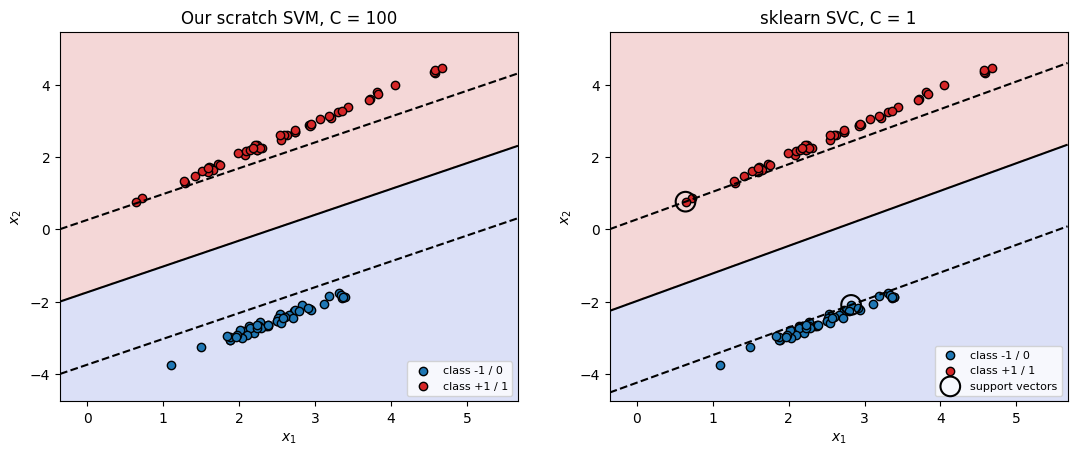

In [11]:
C_ours = 100

model_eq = LinearSVMScratch(lr=0.01, epochs=1000, C=C_ours).fit(X, y_svm)
print("scratch C=100  w:", model_eq.w, " b:", round(model_eq.b, 3))
print("sklearn C=1    w:", sk_model.coef_[0], " b:", round(sk_model.intercept_[0], 3))

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_svm(model_eq.w, model_eq.b, X, y_svm, "Our scratch SVM, C = 100", ax=axes[0])
plot_svm(sk_model.coef_[0], sk_model.intercept_[0], X, y_svm,
         "sklearn SVC, C = 1", support=sk_model.support_, ax=axes[1])
plt.show()

**Check yourself:** `C_ours = 100` gives `w = [-0.3567 0.4989]`, `b ≈ 0.87`, very close to sklearn.

> Where does the remaining small difference come from? What is the general lesson about hyperparameters in libraries?

*Answer:* from the optimizer: we take a fixed number of simple subgradient steps, sklearn solves the problem to high precision. Lesson: a hyperparameter name means nothing without its definition; always read how the library writes the objective.

Our class is intentionally simple and educational; sklearn provides a production-quality implementation.

## Part F. Nonlinear data

### Task 10. When a line is not enough

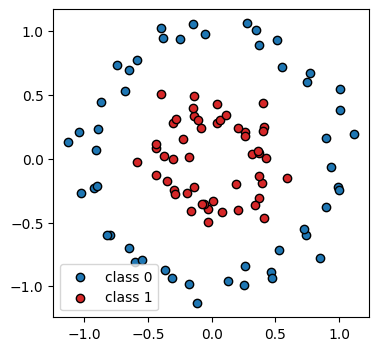

In [12]:
# ---- PROVIDED
from sklearn.datasets import make_circles

X_c, y_c = make_circles(
    n_samples=100,
    noise=0.08,
    factor=0.4,
    random_state=42
)

plt.scatter(X_c[y_c == 0, 0], X_c[y_c == 0, 1], c="tab:blue", edgecolor="k", label="class 0")
plt.scatter(X_c[y_c == 1, 0], X_c[y_c == 1, 1], c="tab:red",  edgecolor="k", label="class 1")
plt.gca().set_aspect("equal")
plt.legend()
plt.show()


def plot_kernel_svm(model, X, y, title, ax=None):
    if ax is None:
        ax = plt.gca()
    x1_min, x1_max = X[:, 0].min() - 0.5, X[:, 0].max() + 0.5
    x2_min, x2_max = X[:, 1].min() - 0.5, X[:, 1].max() + 0.5
    xx1, xx2 = np.meshgrid(np.linspace(x1_min, x1_max, 300),
                           np.linspace(x2_min, x2_max, 300))
    grid = np.c_[xx1.ravel(), xx2.ravel()]
    Z = model.predict(grid).reshape(xx1.shape)
    F = model.decision_function(grid).reshape(xx1.shape)

    ax.contourf(xx1, xx2, Z, alpha=0.2, cmap="coolwarm")
    ax.contour(xx1, xx2, F, levels=[-1, 0, 1], colors="k", linestyles=["--", "-", "--"])
    ax.scatter(X[y == 0, 0], X[y == 0, 1], c="tab:blue", edgecolor="k")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], c="tab:red",  edgecolor="k")
    ax.scatter(X[model.support_, 0], X[model.support_, 1], s=200,
               facecolors="none", edgecolors="k", linewidths=1.2)
    ax.set_aspect("equal")
    ax.set_title(title)

> **Can a straight line solve this problem?**

*Answer:* no. One class is a ring around the other, so any line leaves points of both classes on each side.

`SVC` can use **kernels**, which let the SVM draw curved boundaries. Think of a kernel as *"a different way of measuring similarity between points"*. The interface does not change: `fit`, `predict`.

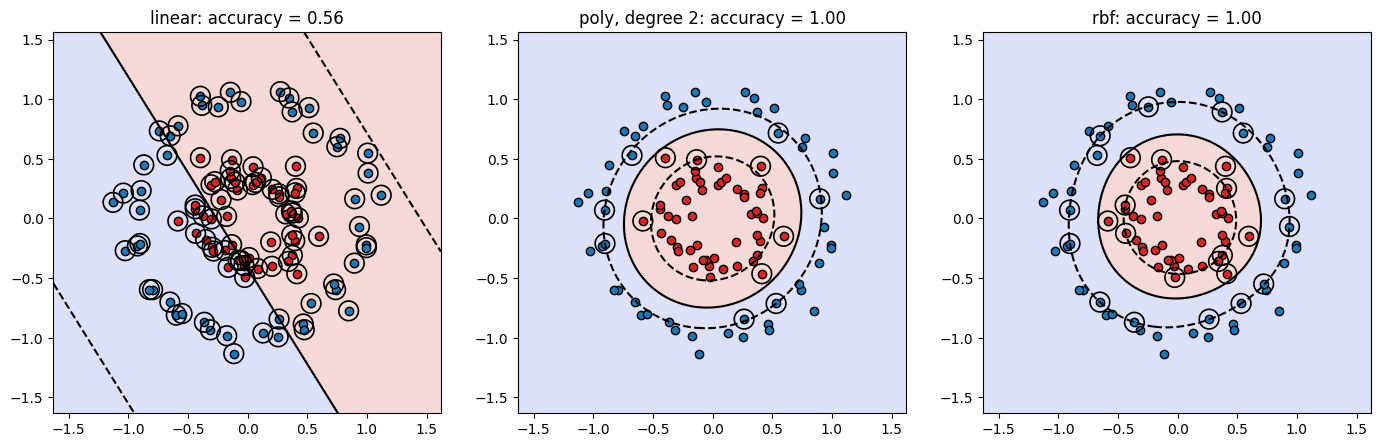

In [13]:
kernels = {
    "linear":         SVC(kernel="linear"),
    "poly, degree 2": SVC(kernel="poly", degree=2, C=1),
    "rbf":            SVC(kernel="rbf", C=1),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, (name, clf) in zip(axes, kernels.items()):
    clf.fit(X_c, y_c)
    acc = np.mean(clf.predict(X_c) == y_c)
    plot_kernel_svm(clf, X_c, y_c, f"{name}: accuracy = {acc:.2f}", ax=ax)
plt.show()

**Check yourself:** training accuracy `0.56` (linear), `1.00` (poly, degree 2), `1.00` (rbf).

> Why is a degree-2 polynomial a natural choice for this particular dataset?

*Answer:* the true boundary is a circle, $x_1^2 + x_2^2 = r^2$, which is an equation of degree 2. A degree-2 kernel can draw exactly that kind of curve.

## Part G. Small experiments

Write your prediction **before** running each cell.

### Task 11. One annoying point

We add a single point labelled $-1$ in the gap, very close to the red cloud, and train with a small and a large $C$. (The learning rate is lowered because large $C$ makes the steps large.)

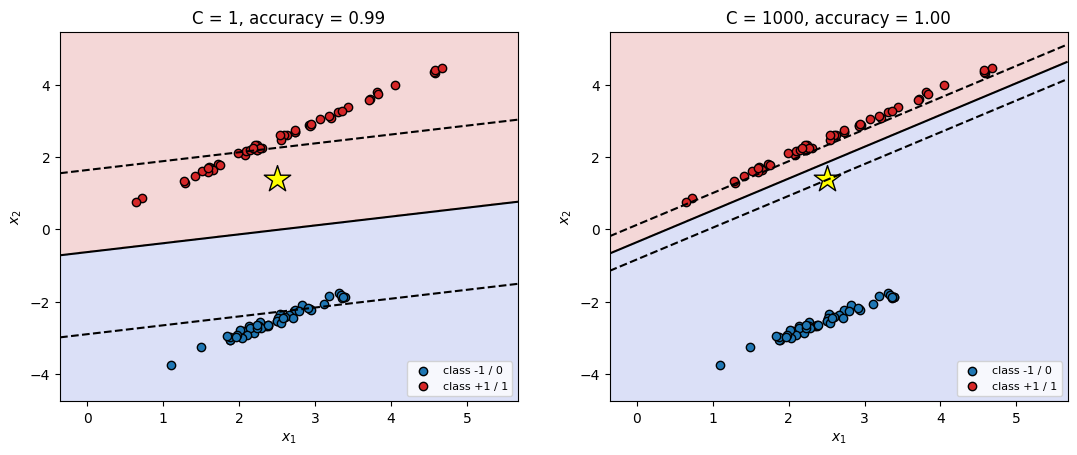

In [14]:
# ---- PROVIDED
outlier = np.array([[2.5, 1.4]])
X_out = np.vstack([X, outlier])
y_out = np.append(y_svm, -1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for ax, C in zip(axes, [1, 1000]):
    m_out = LinearSVMScratch(lr=0.001, epochs=5000, C=C).fit(X_out, y_out)
    acc = np.mean(m_out.predict(X_out) == y_out)
    plot_svm(m_out.w, m_out.b, X_out, y_out, f"C = {C}, accuracy = {acc:.2f}", ax=ax)
    ax.scatter(*outlier[0], marker="*", s=400, c="yellow", edgecolor="k")
plt.show()

*Answer:* with $C = 1$ the model keeps its wide margin and accepts one mistake (accuracy 0.99). With $C = 1000$ it refuses the mistake and squeezes the boundary and the margin to fit one single point (accuracy 1.00, very narrow margin). If that point is noise, this is overfitting.

### Task 12. The `gamma` of the RBF kernel

`gamma` controls how far the influence of each training point reaches.

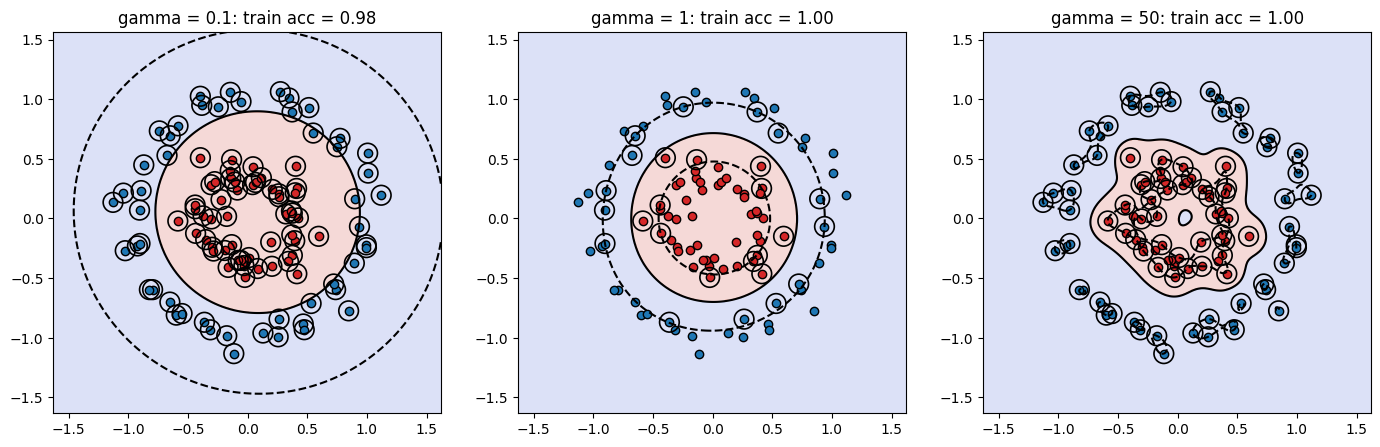

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
for ax, gamma in zip(axes, [0.1, 1, 50]):
    clf = SVC(kernel="rbf", C=1, gamma=gamma).fit(X_c, y_c)
    acc = np.mean(clf.predict(X_c) == y_c)
    plot_kernel_svm(clf, X_c, y_c, f"gamma = {gamma}: train acc = {acc:.2f}", ax=ax)
plt.show()

**Check yourself:** training accuracy `0.98`, `1.00`, `1.00`.

*Answer:* small `gamma` (0.1): each point influences a large region, so the boundary is very smooth and the margin very wide; it misses a couple of points. `gamma = 1` gives a clean circle. Large `gamma` (50): each point only influences its close neighbourhood, so the boundary becomes wiggly, even with a hole in the middle, and almost every point is a support vector. Training accuracy is still 1.00, which shows that training accuracy alone cannot detect overfitting.

## Final comparison

| | Logistic Regression | SVM |
|---|---|---|
| Score | $z = w^Tx + b$ | $f(x) = w^Tx + b$ |
| Output | $p = \sigma(z)$, a probability | sign of $f(x)$, a class |
| Labels | $\{0, 1\}$ | $\{-1, +1\}$ |
| Loss | binary cross-entropy | hinge: $\max(0, 1 - y f(x))$ |
| Who influences the boundary | every point, a little | only the support vectors |
| Main idea | **model the probability of class 1** | **find a boundary with a large margin** |

```python
model.fit(X, y)
model.predict(X)
```

> **Different algorithms can have the same interface.**